In [61]:

# data clean the data 

from spam_filter.data.cleaning import clean_dataset


import  pandas as pd 


Databse_path = "../../../data/processed/emails.csv"


df = pd.read_csv(Databse_path)

df = clean_dataset(df)






Index(['id', 'filename', 'subject', 'body', 'label'], dtype='str')
mssingCols :  set()
Duplicate emails: 50
Emails with conflicting labels: 0
Label order: ['ham' 'spam']


In [62]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier

from spam_filter.data.cleaning import EmailColumn


y = df[EmailColumn.TARGET]
x = df[EmailColumn.TEXT]

# split test and train data

X_train, X_test , y_train, y_test = train_test_split(x,y , random_state=1, test_size=0.2, stratify=y)



X_train.head()


2861    subject: [ILUG-Social] Low Price Tobacco\nbody...
1325    subject: Re: [SAtalk] where can I find the Hab...
1848    subject: The Semantic Web makes me sick\nbody:...
2399    subject: Go-ahead for new-style hospitals\nbod...
571     subject: Re: dylsexics of the wrold, untie!\nb...
Name: text, dtype: str

In [63]:

baselineModel =DummyClassifier( strategy="most_frequent")

baselineModel.fit(X=X_train, y=y_train)


predictions = baselineModel.predict(X_test)



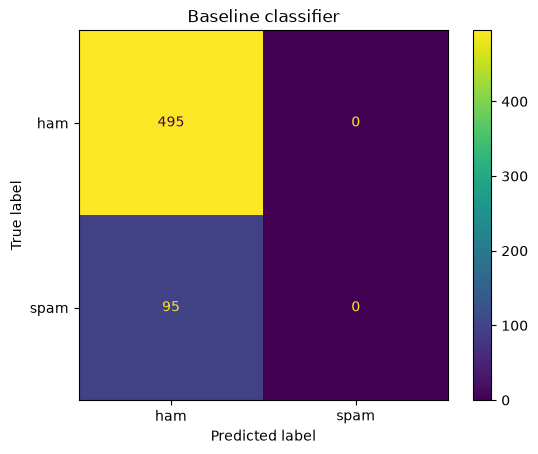

array([[495,   0],
       [ 95,   0]])

In [64]:
from pathlib import Path

from matplotlib import pyplot as plt
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay



def customer_confusion_matrix(predictions, y_test, title, saveFigure = False):
    confusion_matrix_ = confusion_matrix(y_pred=predictions, y_true=y_test)


    ConfusionMatrixDisplay(
    
    confusion_matrix=confusion_matrix_,
    display_labels=["ham", "spam"],
).plot()


    plt.title(title)

    output_path = Path(f"../../../artifacts/{title}_matrix.png")
    output_path.parent.mkdir(parents=True, exist_ok=True)
    if saveFigure:
        plt.savefig(output_path, dpi=150)

    plt.show()
    
    return confusion_matrix_

customer_confusion_matrix(predictions, y_test, "Baseline classifier")


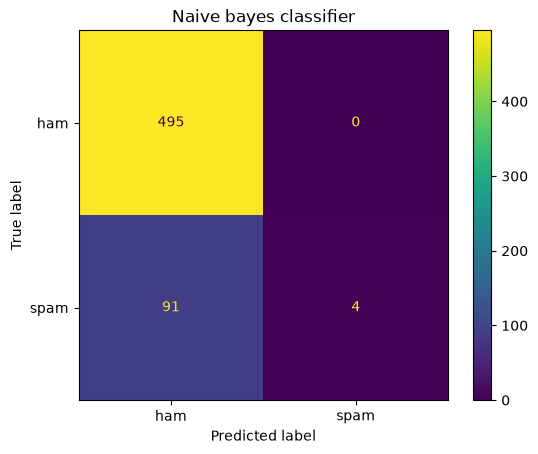

In [65]:


from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import MultinomialNB



modelNb = make_pipeline(
    TfidfVectorizer(),
    MultinomialNB()
)


modelNb.fit(X=X_train, y=y_train)


predictionsnb = modelNb.predict(X=X_test)


confusion_matrixNB = customer_confusion_matrix(predictionsnb,y_test , "Naive bayes classifier")



In [66]:


TN, FP, FN, TP = confusion_matrixNB.ravel()


print("-----Using revel------")
print("True negative" ,  TN)
print("True positive" , TP)
print("False negative" , FN)
print("False positive" , FP)

total = TP + TN + FN + FP

# correct predictions / all emails.

accuracy = (TP + TN ) / total


# correct predictions / all emails.

precision = TP / ( TP + FP)
recall = TP / ( TP + FN)
f1 = 2 * precision * accuracy / (precision + accuracy)

print(f"accuracy {accuracy * 100}% , precision : {precision * 100}% , recall : {recall * 100}% , f1 : {f1* 100}%")



-----Using revel------
True negative 495
True positive 4
False negative 91
False positive 0
accuracy 84.57627118644068% , precision : 100.0% , recall : 4.2105263157894735% , f1 : 91.643709825528%


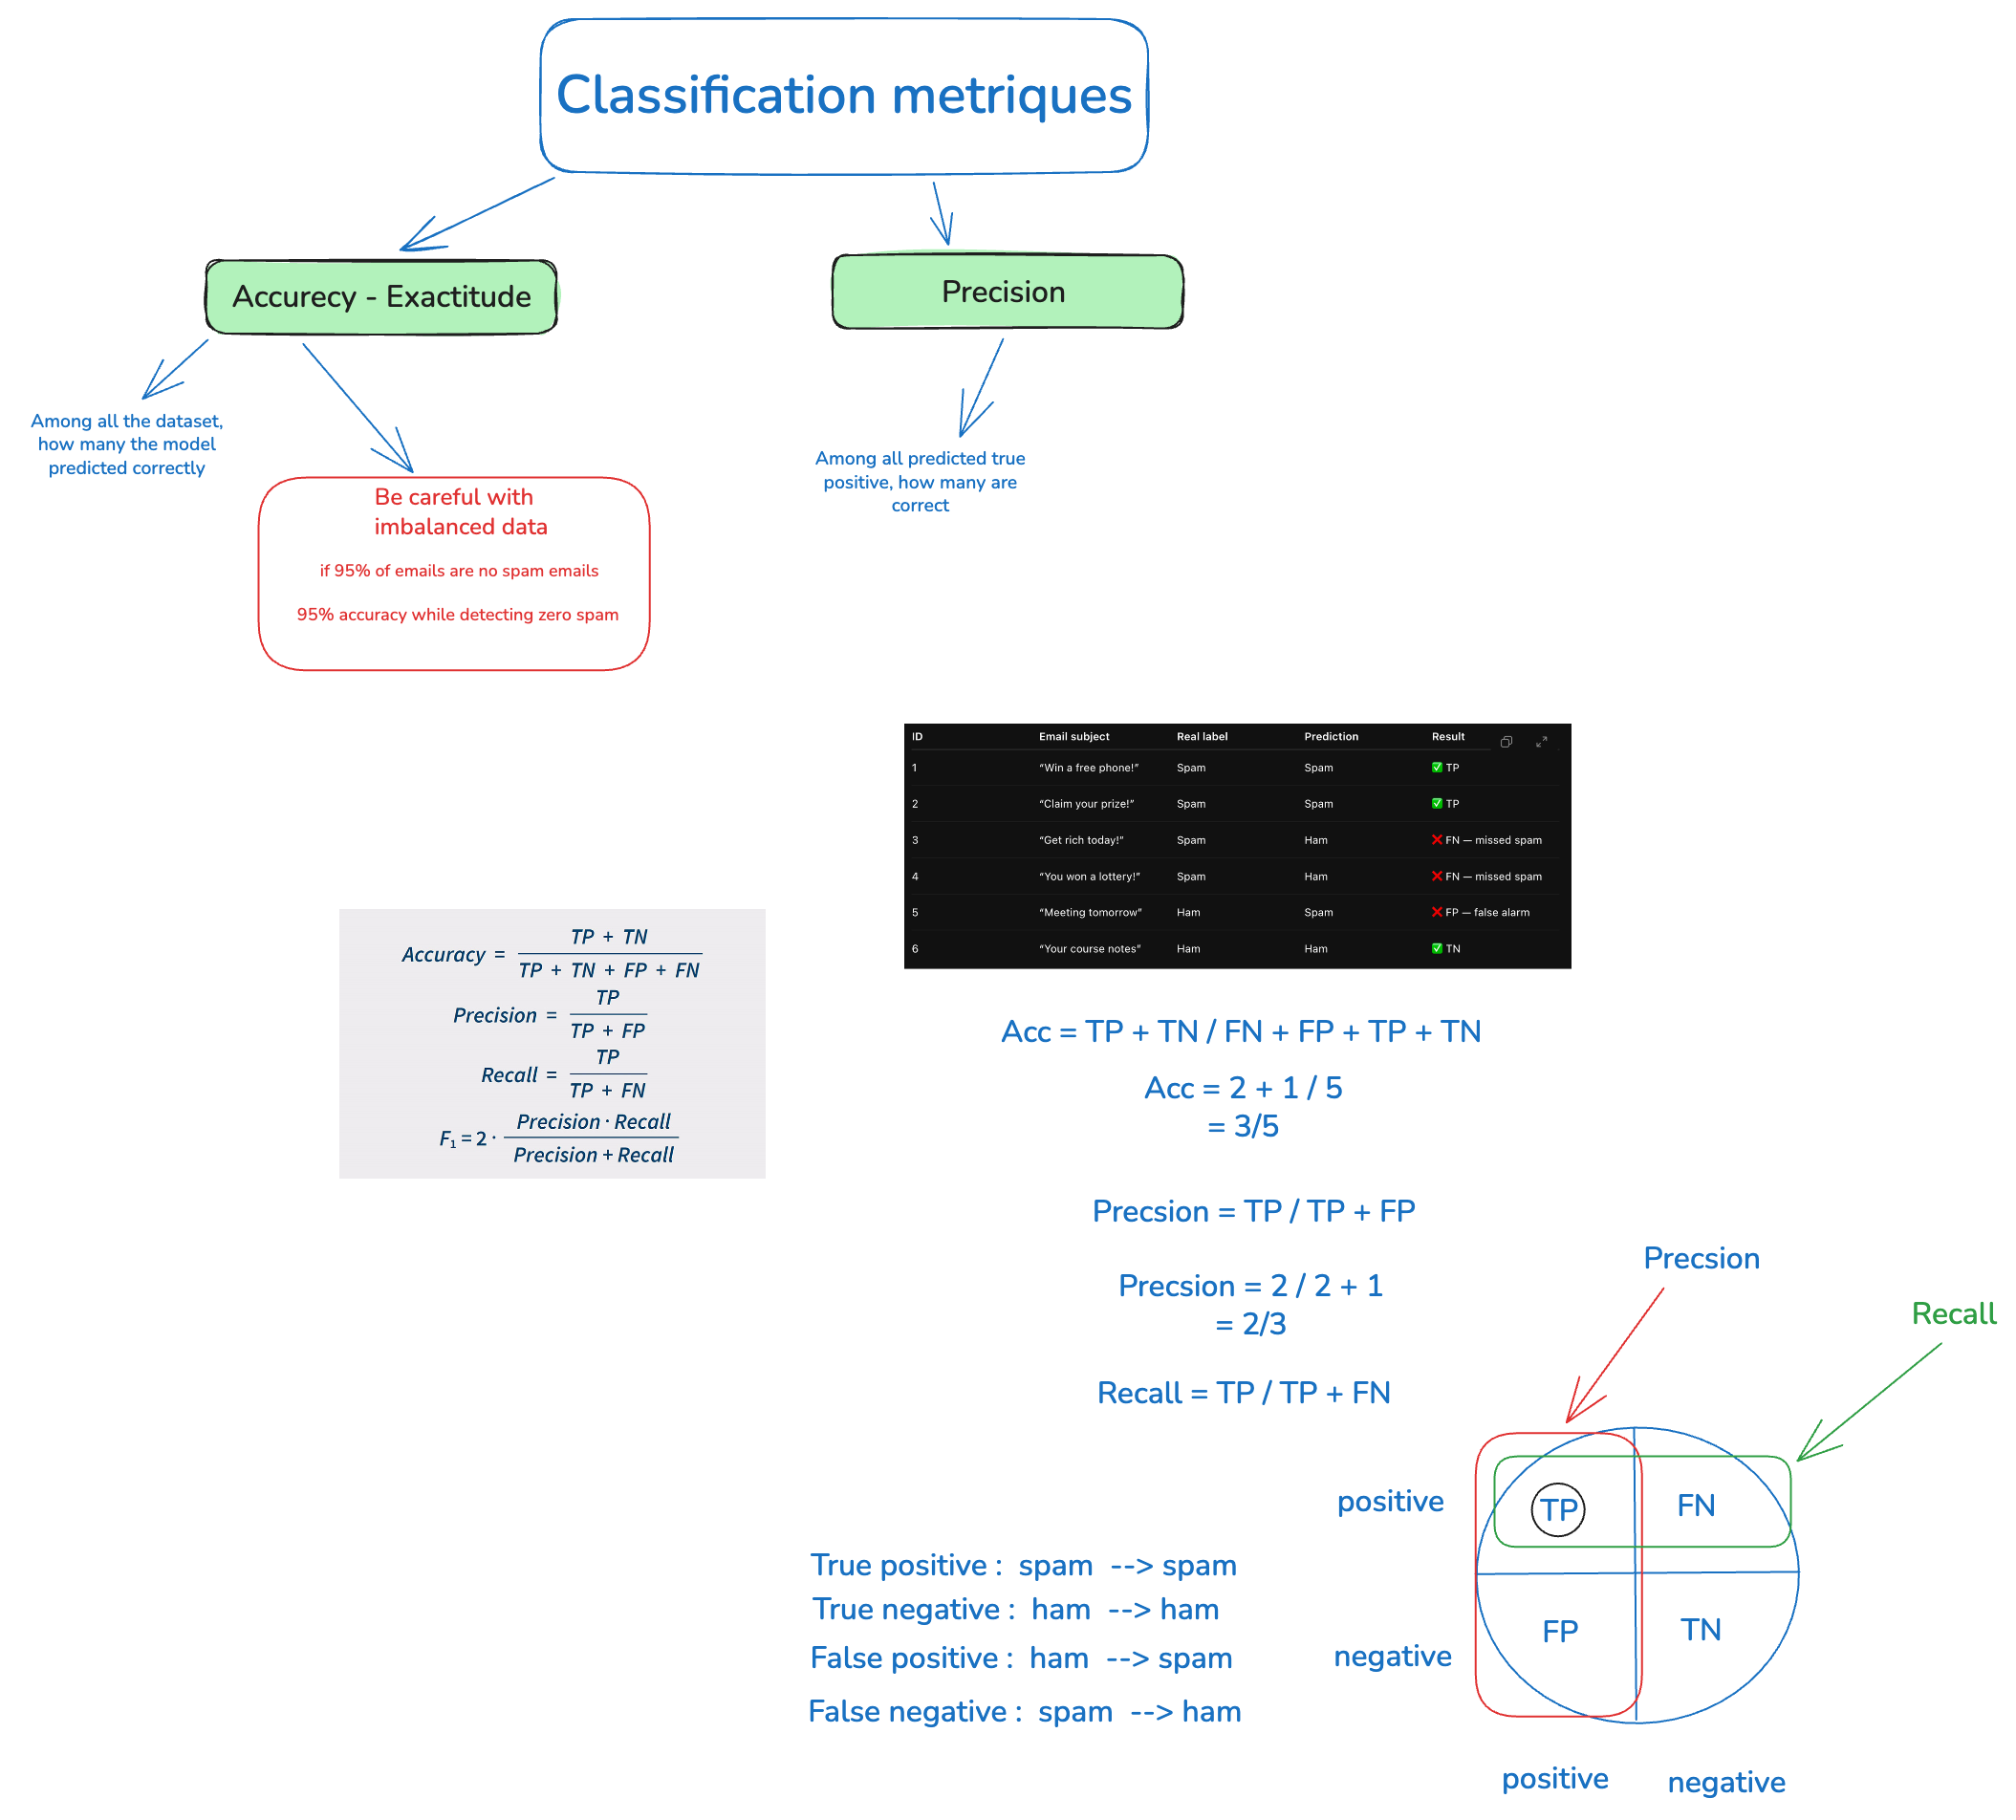

In [67]:
from IPython.display import display, Image



display(Image(filename="../../../artifacts/images/metriques_classification.png"))

In [68]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    f1_score,
    recall_score
)

def clacMetric(y_test , predictions):

    accuracy_scoreNB = accuracy_score(y_true=y_test,y_pred=predictions)
    precision_scoreNB = precision_score(y_true=y_test,y_pred=predictions , zero_division=0, pos_label=1)
    recall_scoreNB = recall_score(y_true=y_test,y_pred=predictions ,zero_division=0, pos_label=1)
    f1_scoreNB = f1_score(y_true=y_test,y_pred=predictions ,zero_division=0, pos_label=1)






    print(f"accuracy {accuracy_scoreNB * 100:.2f}% , precision : {precision_scoreNB * 100:.2f}% , recall : {recall_scoreNB * 100:.2f}% , f1 : {f1_scoreNB* 100:.2f}%")
    

clacMetric(y_test , predictions=predictionsnb)


accuracy 84.58% , precision : 100.00% , recall : 4.21% , f1 : 8.08%



----- Naive Bayes: validation -----


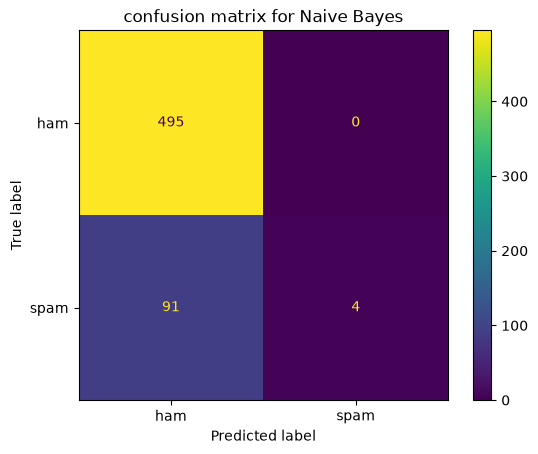

----- Naive Bayes: metrics -----
accuracy 84.58% , precision : 100.00% , recall : 4.21% , f1 : 8.08%
----- Naive Bayes: end metrics -----

----- Balanced Logistic Regression: validation -----


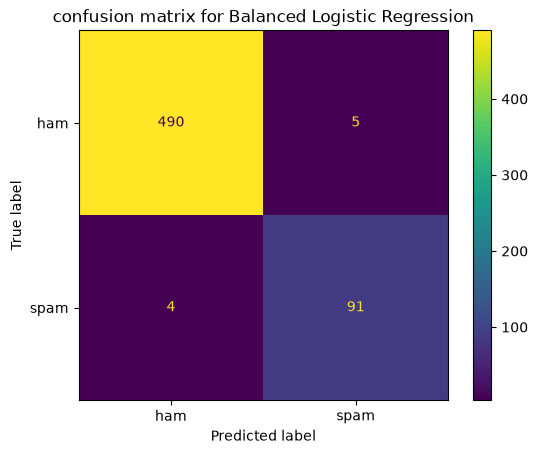

----- Balanced Logistic Regression: metrics -----
accuracy 98.47% , precision : 94.79% , recall : 95.79% , f1 : 95.29%
----- Balanced Logistic Regression: end metrics -----


In [69]:



from sklearn.linear_model import LogisticRegression

models = {
    
    "Naive Bayes": make_pipeline(
        TfidfVectorizer(),
        MultinomialNB(),
    ),
    "Balanced Logistic Regression": make_pipeline(
        TfidfVectorizer(),
        LogisticRegression(class_weight="balanced", max_iter=1000),
    ),
}

for name, model in models.items():
    
    # print(model)
    model.fit(X=X_train, y=y_train)
    predictions=model.predict(X=X_test)
    
    print(f"\n----- {name}: validation -----")
    cc=customer_confusion_matrix(predictions, y_test=y_test, title=f"confusion matrix for {name}", saveFigure=True)
    
    # print(cc)
    
    print(f"----- {name}: metrics -----")
    clacMetric(y_test, predictions=predictions)
    print(f"----- {name}: end metrics -----")
    
    
    
    
    
    

In [70]:
# from sklearn.feature_extraction.text import TfidfVectorizer

# emails = [
#     "hello friend",
#     "hello meeting",
#     "hello prize prize",
# ]

# vectorizer = TfidfVectorizer()

# X = vectorizer.fit_transform(emails)

# print(vectorizer.get_feature_names_out())
# print(X.toarray().round(2))